# 04 — Categorical Encoding Without Leakage

[Previous](./03_Missing_Values_and_Scaling.ipynb) | [Repository guide](../README.md) | [Next](./05_Feature_Engineering.ipynb)

> This public copy includes the saved Kaggle outputs, so every table, chart, and score can be inspected on GitHub.

**Goal:** compare safe ways to convert category labels into numbers while keeping the model, preprocessing, and validation fixed.

IDs remain excluded because they are unique. `solution.csv` is never read.

### Read the setup

- `import` loads a Python tool; `as` gives it a short name.
- `pd` handles tables, `np` handles numerical calculations, and `plt` draws charts.
- The `sklearn` tools implement the methods explained in this chapter.


In [1]:
# Tables, numerical calculations, and charts.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, TargetEncoder

# The column we want to predict: 1 = scored, 0 = missed.
TARGET = "is_scored"
# These identifier columns are excluded from the course's model inputs.
ID_COLUMNS = ["id", "kicker_id", "keeper_id", "match_id"]
# A fixed seed makes randomized splits and experiments repeatable.
RANDOM_STATE = 42
# Optional display settings: readable tables and chart grids.
pd.set_option("display.float_format", "{:.4f}".format)
plt.style.use("seaborn-v0_8-whitegrid")


### Load the competition data

Attach the competition under Kaggle's **Input** panel. `DATA_DIR` is its folder;
`pd.read_csv` opens a CSV as a table. `train` contains known answers; `test`
contains the rows we will eventually predict.

For Colab, upload the extracted CSV files and set `DATA_DIR` to `/content`;
the [repository guide](../README.md#colab) explains the output-path change.


In [3]:
DATA_DIR = "/kaggle/input/competitions/penalty-kick-outcome-prediction-challenge"

train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")

# Check that only train contains labels and both files have the same inputs.
assert TARGET in train and TARGET not in test
assert set(train.columns) - {TARGET} == set(test.columns)
print(f"Source: {DATA_DIR}")
print(f"Train: {train.shape} | Test: {test.shape}")
print("solution.csv: intentionally not loaded")

Source: /kaggle/input/competitions/penalty-kick-outcome-prediction-challenge
Train: (20000, 20) | Test: (6000, 19)
solution.csv: intentionally not loaded


## 1. Measure the categories

A **categorical feature** contains labels rather than measured quantities. **Cardinality** is its number of different labels. Low cardinality makes one-hot encoding practical; unseen test labels require an encoder that can handle unknown values.

Frequency and scoring rate answer different questions:

- **Frequency = category rows / all rows.** It uses no target. It reveals rare labels, supports frequency encoding, and helps detect train/test shift.
- **Scoring rate = scored rows / category rows.** It uses the target. It can suggest predictive categories, target encoding, or interactions such as home venue plus home crowd.

A rare category’s scoring rate is noisy, so always read the rate together with its row count.


In [4]:
FEATURES = [column for column in train.columns if column not in [TARGET] + ID_COLUMNS]
NUMERICAL = train[FEATURES].select_dtypes(include=np.number).columns.tolist()
CATEGORICAL = [column for column in FEATURES if column not in NUMERICAL]
category_audit = pd.DataFrame({
    "cardinality": train[CATEGORICAL].nunique(dropna=False),
    "missing_%": train[CATEGORICAL].isna().mean().mul(100),
    "unseen_in_test": [len(set(test[column].dropna()) - set(train[column].dropna())) for column in CATEGORICAL],
}).sort_values("cardinality")
display(category_audit)
print(f"All {len(CATEGORICAL)} model categories have low cardinality; one-hot encoding is a strong default.")

,cardinality,missing_%,unseen_in_test
crowd_behind_goal,2,0.0000,0
home_or_away,3,0.0000,0
pitch_condition,4,0.0000,0
match_type,5,0.0000,0
jersey_color,9,3.1950,0


All 5 model categories have low cardinality; one-hot encoding is a strong default.


### Concrete dataset example: frequency versus scoring rate

For `match_type`, frequency says how common each match type is. Scoring rate says how often penalties were scored inside it. A rate difference may motivate a feature, but it must still improve OOF validation.


,rows,scored,frequency,scoring_rate
match_type,,,,
League,9330,4128,0.4665,0.4424
Cup,4937,2007,0.2469,0.4065
Final,2516,1257,0.1258,0.4996
Friendly,1876,898,0.0938,0.4787
Playoff,1341,711,0.0670,0.5302


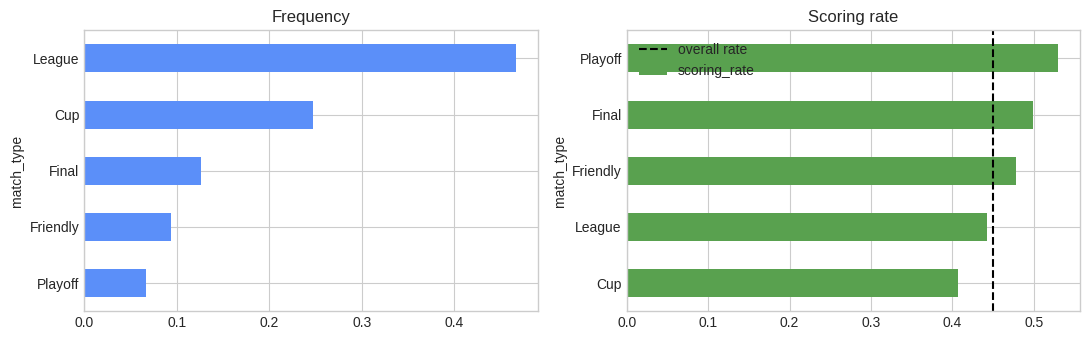

In [5]:
example_category = "match_type"
category_example = train.groupby(example_category, dropna=False)[TARGET].agg(rows="size", scored="sum")
category_example["frequency"] = category_example["rows"] / len(train)
category_example["scoring_rate"] = category_example["scored"] / category_example["rows"]
display(category_example.sort_values("frequency", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
category_example.sort_values("frequency")["frequency"].plot.barh(ax=axes[0], color="#5b8ff9", title="Frequency")
category_example.sort_values("scoring_rate")["scoring_rate"].plot.barh(ax=axes[1], color="#59a14f", title="Scoring rate")
axes[1].axvline(train[TARGET].mean(), color="black", linestyle="--", label="overall rate")
axes[1].legend()
plt.tight_layout()
plt.show()


## 2. Encoding methods

| Method | What replaces `Home/Away/...`? | Main use and trade-off |
|---|---|---|
| One-hot | One `0/1` column per label | Clear and safe; wide with many labels |
| Ordinal | Arbitrary integers such as `0,1,2` | Compact; invents an order |
| Frequency | Training-fold category frequency | Target-free and compact; two labels can share a value |
| Cross-fitted target | Smoothed training-fold scoring rate | Can capture target signal; leaks if a row helps encode itself |

Frequency encoding can be treated as a new feature. Scoring rate can also inspire interactions or target encoding, but it cannot justify dropping a column by itself.


### Why target encoding needs cross-fitting

**Target leakage** occurs if a row’s true answer helps create its own input. During `fit_transform`, scikit-learn’s `TargetEncoder` uses internal folds, so each training row receives a value learned from other rows. The outer five folds still provide the final evaluation.

In [6]:
class FrequencyEncoder(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        values = np.asarray(X, dtype=object)
        self.maps_ = []
        for column_index in range(values.shape[1]):
            labels, counts = np.unique(values[:, column_index], return_counts=True)
            self.maps_.append(dict(zip(labels, counts / len(values))))
        return self

    def transform(self, X):
        values = np.asarray(X, dtype=object)
        encoded = np.zeros(values.shape, dtype=float)
        for column_index, mapping in enumerate(self.maps_):
            encoded[:, column_index] = [mapping.get(value, 0.0) for value in values[:, column_index]]
        return encoded

In [7]:
# X contains model inputs; y contains the known answers.
X = train[FEATURES]
y = train[TARGET].astype(int)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def build_pipeline(encoder):
    preprocessing = ColumnTransformer([
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), NUMERICAL),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", encoder),
        ]), CATEGORICAL),
    ])
    return Pipeline([
        ("preprocessing", preprocessing),
        ("model", LogisticRegression(max_iter=10000, random_state=RANDOM_STATE)),
    ])

def evaluate(name, encoder):
    class_probabilities = cross_val_predict(build_pipeline(encoder), X, y, cv=cv, method="predict_proba", n_jobs=-1)
    # Column 0 = missed; column 1 = scored. Keep the scoring probability.
    probabilities = class_probabilities[:, 1]
    predictions = (probabilities >= 0.50).astype(int)
    fold_f1 = []
    # Score each validation fold separately to check consistency.
    for unused_training_rows, validation_rows in cv.split(X, y):
        fold_score = f1_score(y.iloc[validation_rows], predictions[validation_rows])
        fold_f1.append(fold_score)
    return {
        "method": name, "f1": f1_score(y, predictions), "f1_std": np.std(fold_f1, ddof=1),
        "precision": precision_score(y, predictions), "recall": recall_score(y, predictions),
        "accuracy": accuracy_score(y, predictions), "roc_auc": roc_auc_score(y, probabilities),
    }

In [8]:
encoding_specs = [
    ("One-hot encoding", OneHotEncoder(handle_unknown="ignore")),
    ("Ordinal encoding", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
    ("Frequency encoding", FrequencyEncoder()),
    ("Cross-fitted target encoding", TargetEncoder(target_type="binary", smooth="auto", cv=5, shuffle=True, random_state=RANDOM_STATE)),
]
results = pd.DataFrame([evaluate(name, encoder) for name, encoder in encoding_specs])
results = results.sort_values("f1", ascending=False).reset_index(drop=True)
display(results)

,method,f1,f1_std,precision,recall,accuracy,roc_auc
0,One-hot encoding,0.8482,0.0054,0.8530,0.8435,0.8641,0.9404
1,Cross-fitted target encoding,0.8447,0.0045,0.8500,0.8394,0.8610,0.9385
2,Ordinal encoding,0.7654,0.0021,0.7771,0.7540,0.7920,0.8801
3,Frequency encoding,0.7486,0.0047,0.7655,0.7324,0.7786,0.8649


### What the encoders do to one dataset value

For a `Final` match, one-hot records membership, frequency records how common finals are, and target encoding records a cross-fitted estimate of the final-match scoring rate. Only the pipeline version is used for scoring.


In [9]:
label = train["match_type"].dropna().iloc[0]
frequency_value = (train["match_type"] == label).mean()
illustrative_rate = train.loc[train["match_type"] == label, TARGET].mean()
display(pd.DataFrame({
    "representation": ["raw label", "one-hot idea", "frequency", "scoring-rate idea"],
    "example": [label, f"match_type_{label} = 1", f"{frequency_value:.4f}", f"{illustrative_rate:.4f}"],
}))
print("The displayed full-data scoring rate is explanatory only; the evaluated TargetEncoder uses internal cross-fitting.")


,representation,example
0,raw label,Friendly
1,one-hot idea,match_type_Friendly = 1
2,frequency,0.0938
3,scoring-rate idea,0.4787


The displayed full-data scoring rate is explanatory only; the evaluated TargetEncoder uses internal cross-fitting.


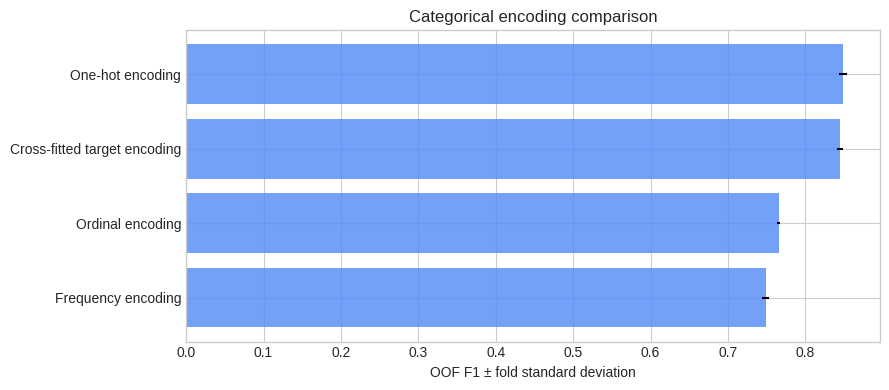

In [10]:
ordered = results.sort_values("f1")
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(ordered["method"], ordered["f1"], xerr=ordered["f1_std"], color="#5b8ff9", alpha=.85)
ax.set(title="Categorical encoding comparison", xlabel="OOF F1 ± fold standard deviation", ylabel="")
plt.tight_layout()
plt.show()

## 3. Decision

A tiny F1 difference smaller than ordinary fold variation is not a reliable win. For low-cardinality categories, one-hot remains the simplest interpretation-friendly choice unless another method shows a repeatable gain.

In [11]:
best = results.iloc[0]
one_hot = results.loc[results["method"].eq("One-hot encoding")].iloc[0]
print(f"Best point estimate: {best['method']} | F1 {best['f1']:.4f}")
print(f"Difference from one-hot: {best['f1'] - one_hot['f1']:+.4f}")
if best['f1'] - one_hot['f1'] < one_hot['f1_std']:
    print("Decision: no clear gain beyond fold variation; keep one-hot encoding.")
else:
    print("Decision: the best encoder deserves a repeated-CV check.")

Best point estimate: One-hot encoding | F1 0.8482
Difference from one-hot: +0.0000
Decision: no clear gain beyond fold variation; keep one-hot encoding.


## Other alternatives

- **Count encoding:** uses category counts instead of proportions; similar to frequency encoding.
- **Binary encoding:** converts category numbers into binary digits; compact for high cardinality.
- **Hash encoding:** maps labels into a fixed number of columns; fast, but collisions mix categories.
- **Leave-one-out encoding:** uses target means while excluding the current row; still needs outer-fold safety.
- **Weight of Evidence:** uses class-odds ratios; binary-target specific and must be cross-fitted.
- **CatBoost native encoding:** ordered target statistics built into CatBoost; compared later with the model itself.

The last methods are most useful for high-cardinality categories; this dataset’s model categories are small.

In [12]:
# Path is used only to name the files saved in Kaggle's Output panel.
from pathlib import Path

results_dir = Path("/kaggle/working")
results_dir.mkdir(parents=True, exist_ok=True)
output_path = results_dir / "04_categorical_encoding.csv"
results.to_csv(output_path, index=False)
print(f"Saved: {output_path}")

Saved: /kaggle/working/04_categorical_encoding.csv


## Why this encoding decision is justified

**Technical evidence:** the model categories have low cardinality, no important unseen-label problem appears, and one-hot gives the best or statistically indistinguishable OOF F1.

**Theoretical reason:** one-hot makes no false ordering assumption and keeps each label interpretable. Frequency is useful for rarity; scoring rate is useful for target-aware hypotheses, but target-based encoding requires cross-fitting to prevent leakage.
